# 01 – EDA: Telco Churn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
df = pd.read_csv('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [3]:
df.shape

(7043, 21)

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df.sum()

customerID          7590-VHVEG5575-GNVDE3668-QPYBK7795-CFOCW9237-H...
gender              FemaleMaleMaleMaleFemaleFemaleMaleFemaleFemale...
SeniorCitizen                                                    1142
Partner             YesNoNoNoNoNoNoNoYesNoYesNoYesNoNoYesNoNoYesNo...
Dependents          NoNoNoNoNoNoYesNoNoYesYesNoNoNoNoYesNoYesYesNo...
tenure                                                         227990
PhoneService        NoYesYesNoYesYesYesNoYesYesYesYesYesYesYesYesY...
MultipleLines       No phone serviceNoNoNo phone serviceNoYesYesNo...
InternetService     DSLDSLDSLDSLFiber opticFiber opticFiber opticD...
OnlineSecurity      NoYesYesYesNoNoNoYesNoYesYesNo internet servic...
OnlineBackup        YesNoYesNoNoNoYesNoNoYesNoNo internet serviceN...
DeviceProtection    NoYesNoYesNoYesNoNoYesNoNoNo internet serviceY...
TechSupport         NoNoNoYesNoNoNoNoYesNoNoNo internet serviceNoN...
StreamingTV         NoNoNoNoNoYesYesNoYesNoNoNo internet serviceYe...
StreamingMovies     

In [9]:
total_numeric = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [10]:
total_numeric.isna().sum()

np.int64(11)

In [11]:
mask = total_numeric.isna()

In [12]:
df.loc[mask, ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [14]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)

In [15]:
df['TotalCharges'].dtype

dtype('float64')

In [16]:
df['TotalCharges'].isna().sum()

np.int64(0)

In [17]:
df.loc[mask, ['customerID', 'tenure', 'TotalCharges']]

,customerID,tenure,TotalCharges
488,4472-LVYGI,0,0.0
753,3115-CZMZD,0,0.0
936,5709-LVOEQ,0,0.0
1082,4367-NUYAO,0,0.0
1340,1371-DWPAZ,0,0.0
3331,7644-OMVMY,0,0.0
3826,3213-VVOLG,0,0.0
4380,2520-SGTTA,0,0.0
5218,2923-ARZLG,0,0.0
6670,4075-WKNIU,0,0.0


### Fixing `TotalCharges`

**Problem:** `TotalCharges` was stored as text (`object`) instead of a number. `isna()` showed 0 missing values, but converting the column with `pd.to_numeric(errors='coerce')` exposed **11 rows** whose value was a blank space (`" "`).

**Why it was missing:** all 11 customers have `tenure = 0`. They are brand-new customers who haven't been billed yet, so their true total charges are **0**.

**Decision: fill with 0.**
- Not the median: that would invent charges (~₹1,400) for customers who have paid nothing.
- Not dropping: these rows share a pattern (they're all brand-new customers), so dropping them would remove that group from the data, and new customers will keep appearing once the model is in use.

**Lesson:** missing values don't always look like `NaN`. Find out *why* a value is missing before deciding how to fill it.

In [19]:
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

In [20]:
df['SeniorCitizen'].value_counts()

SeniorCitizen
No     5901
Yes    1142
Name: count, dtype: int64

In [21]:
df['churn'] = (df['Churn'] == 'Yes').astype(int)

In [22]:
df['churn'].mean()

np.float64(0.2653698707936959)

In [23]:
from sklearn.model_selection import train_test_split

In [25]:
train_df, test_df = train_test_split (
    df, 
    test_size = 0.2,
    stratify = df['churn'],
    random_state = 42
)

In [26]:
print(train_df.shape, train_df['churn'].mean())
print(test_df.shape, test_df['churn'].mean())

(5634, 22) 0.2653532126375577
(1409, 22) 0.2654364797728886


In [27]:
train_df.to_csv('../data/processed/train.csv', index=False)
test_df.to_csv('../data/processed/test.csv', index=False)

### Train/test split done

From here on, **all EDA uses `train_df` only.**
`test_df` is **locked away until final evaluation**, so that it can give an honest estimate of how the model will perform on new customers.

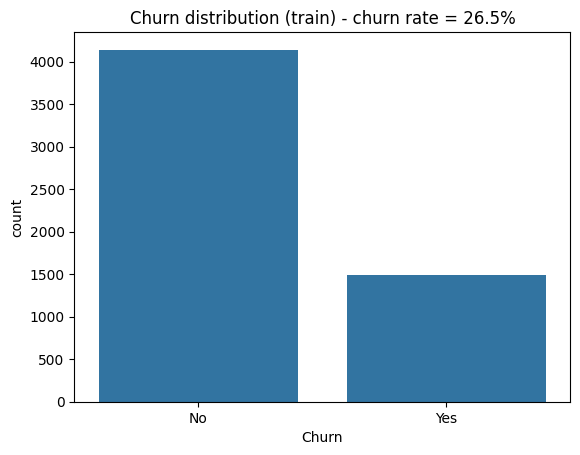

In [33]:
sns.countplot(data=train_df,x='Churn')
plt.title(f"Churn distribution (train) - churn rate = {train_df['churn'].mean():.1%}")
plt.savefig('../reports/figures/target_distribution.png', dpi=120, bbox_inches='tight')
plt.show()

### Why accuracy is misleading here

**Accuracy** = correct predictions ÷ all predictions

We know that **26.5%** of customers churn, so **73.5%** don't.
A "model" that always predicts **"No churn"** is correct for every non-churner, so it gets **73.5% accuracy** without learning anything.

This is useless to the customer success team. They need to know **which customers** will churn, not how many, so they can offer those customers a discount. This model flags **zero** customers, so it catches **zero churners** (recall = 0%).

**Takeaway:** on imbalanced data, accuracy alone is misleading. We'll judge models on **recall, precision and ROC-AUC**, and any real model must clearly beat this 73.5% baseline.

#### Recall: the metric that exposes this
**Recall** = churners the model caught ÷ all actual churners

*"Of all the customers who actually churned, what fraction did we find?"*

The training set has about **1,495 churners**. The "always No" model flags none of them:

> Recall = 0 ÷ 1,495 = **0%**

- **Accuracy** asks: *how often is the model right, across everyone?* It gets credit for the non-churners.
- **Recall** asks: *how many of the customers we care about did we find?* Non-churners don't count.

Its partner, **precision** = churners caught ÷ all customers flagged, measures false alarms (wasted discounts).